# Data science en la piscifactoría

Una piscifactoría quiere estimar el peso de los peces a partir de las medidas obtenidas por un sistema de visión artificial. En este notebook construiremos y compararemos modelos de regresión para predecir el peso en gramos.

Usaremos el archivo `Fish.csv`, que debe estar en la misma carpeta que este notebook. La variable objetivo será `Weight`; las entradas serán la especie y las medidas morfológicas.

| Variable | Significado |
|---|---|
| `Species` | Especie del pez |
| `Weight` | Peso en gramos (variable objetivo) |
| `Length1`, `Length2`, `Length3` | Tres medidas de longitud en centímetros |
| `Height` | Altura en centímetros |
| `Width` | Ancho en centímetros |

Seguiremos un flujo similar al ejemplo de regresión polinómica: exploraremos los datos, compararemos una regresión lineal con una polinómica de grado 2 y evaluaremos su capacidad de generalización.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

fish = pd.read_csv("Fish.csv")
display(fish.head())
print(f"Filas y columnas: {fish.shape}")
print(f"\nColumnas: {fish.columns.tolist()}")

,Species,Weight,Length1,Length2,Length3,Height,Width
0,Bream,242.0,23.2,25.4,30.0,11.5200,4.0200
1,Bream,290.0,24.0,26.3,31.2,12.4800,4.3056
2,Bream,340.0,23.9,26.5,31.1,12.3778,4.6961
3,Bream,363.0,26.3,29.0,33.5,12.7300,4.4555
4,Bream,430.0,26.5,29.0,34.0,12.4440,5.1340


Filas y columnas: (159, 7)

Columnas: ['Species', 'Weight', 'Length1', 'Length2', 'Length3', 'Height', 'Width']


## 1. Exploración de los datos

Antes de ajustar modelos, comprobamos los tipos de datos, los valores ausentes y los duplicados. También resumimos las variables numéricas y observamos cómo se distribuyen los pesos por especie.

In [ ]:
display(fish.info())
display(fish.describe(include="all").T)
print("Valores ausentes por columna:")
display(fish.isna().sum())
print(f"Filas duplicadas: {fish.duplicated().sum()}")

<class 'pandas.DataFrame'>
RangeIndex: 159 entries, 0 to 158
Data columns (total 7 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Species  159 non-null    str    
 1   Weight   159 non-null    float64
 2   Length1  159 non-null    float64
 3   Length2  159 non-null    float64
 4   Length3  159 non-null    float64
 5   Height   159 non-null    float64
 6   Width    159 non-null    float64
dtypes: float64(6), str(1)
memory usage: 8.8 KB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Species,159,7,Perch,56,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Weight,159.0,NaN,NaN,NaN,398.326415,357.978317,0.0,120.0,273.0,650.0,1650.0
Length1,159.0,NaN,NaN,NaN,26.24717,9.996441,7.5,19.05,25.2,32.7,59.0
Length2,159.0,NaN,NaN,NaN,28.415723,10.716328,8.4,21.0,27.3,35.5,63.4
Length3,159.0,NaN,NaN,NaN,31.227044,11.610246,8.8,23.15,29.4,39.65,68.0
Height,159.0,NaN,NaN,NaN,8.970994,4.286208,1.7284,5.9448,7.786,12.3659,18.957
Width,159.0,NaN,NaN,NaN,4.417486,1.685804,1.0476,3.38565,4.2485,5.5845,8.142


Valores ausentes por columna:


Species    0
Weight     0
Length1    0
Length2    0
Length3    0
Height     0
Width      0
dtype: int64

Filas duplicadas: 0


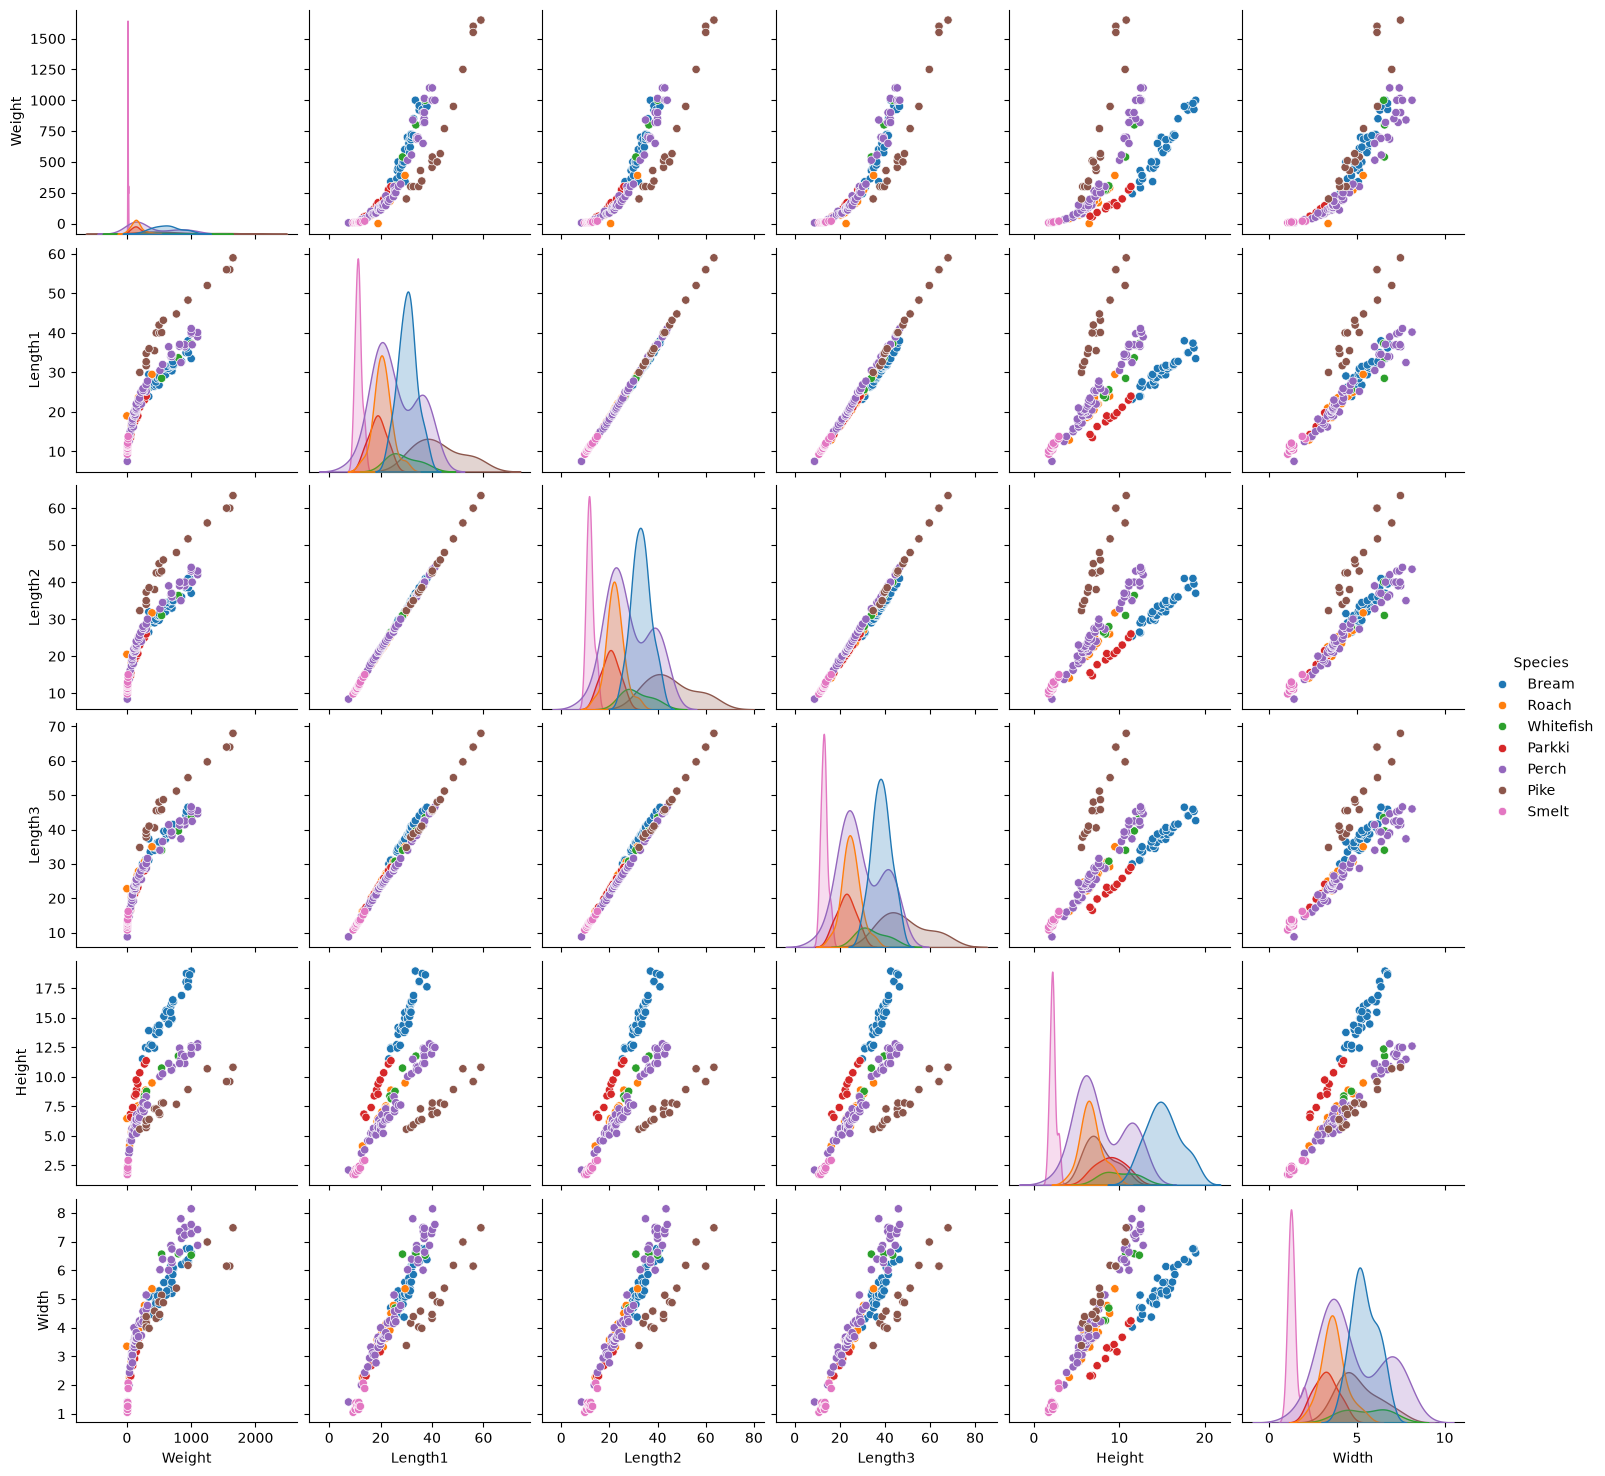

In [ ]:
sns.pairplot(fish, hue="Species")

Podemos hacer un boxplot para ver si la especie influye en el peso, para reforzar el anterior análisis

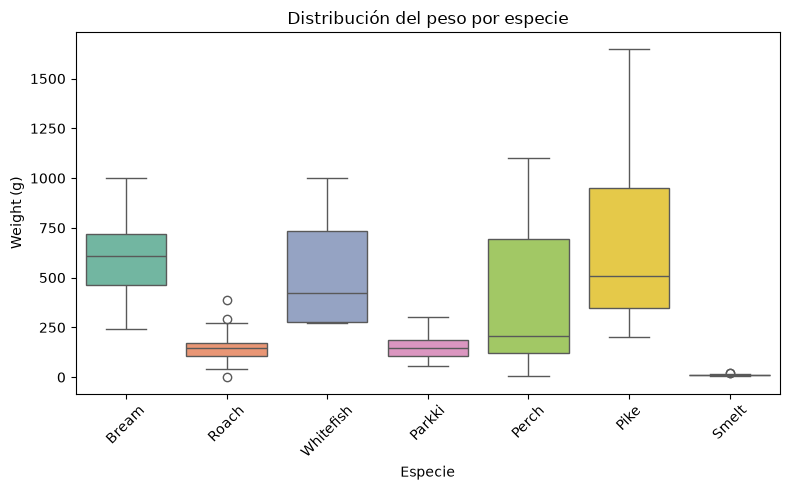

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=fish, x="Species", y="Weight", hue="Species", palette="Set2", legend=False)
plt.title("Distribución del peso por especie")
plt.xlabel("Especie")
plt.ylabel("Weight (g)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Los gráficos paracen mostrar una relación de los predictores lineal pero con cierta curvatura, y parece que la especie podría ser un buen indicador a la hora de predecir el peso.

Separamos el conjunto de Entrenamiento y Test:

In [ ]:
target = "Weight"
X = fish.drop(columns=target)
y = fish[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=X["Species"])


Vamos a transformar la variable categórica especie en numérica utilizando OneHotEncoder()

In [ ]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False).set_output(transform="pandas")
X_train_cod_species = encoder.fit_transform(X_train[["Species"]])
X_test_cod_species = encoder.transform(X_test[["Species"]])

# Juntamos las columnas de OneHot con el dataframe original y elimnamos la columna Species original
X_train_cod_species = pd.concat([X_train.drop(columns="Species"), X_train_cod_species], axis=1)
X_test_cod_species = pd.concat([X_test.drop(columns="Species"), X_test_cod_species], axis=1)

In [ ]:
X_train_cod_species

,Length1,Length2,Length3,Height,Width,Species_Bream,Species_Parkki,Species_Perch,Species_Pike,Species_Roach,Species_Smelt,Species_Whitefish
69,21.2,23.0,25.8,10.3458,3.6636,0.0,1.0,0.0,0.0,0.0,0.0,0.0
149,10.7,11.2,12.4,2.0832,1.2772,0.0,0.0,0.0,0.0,0.0,1.0,0.0
79,17.2,19.0,20.2,5.6358,3.0502,0.0,0.0,1.0,0.0,0.0,0.0,0.0
0,23.2,25.4,30.0,11.5200,4.0200,1.0,0.0,0.0,0.0,0.0,0.0,0.0
21,31.4,34.0,39.2,15.9936,5.3704,1.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
18,30.9,33.5,38.6,15.6330,5.1338,1.0,0.0,0.0,0.0,0.0,0.0,0.0
133,36.0,38.5,41.0,6.3960,3.9770,0.0,0.0,0.0,1.0,0.0,0.0,0.0
155,11.7,12.4,13.5,2.4300,1.2690,0.0,0.0,0.0,0.0,0.0,1.0,0.0
95,21.5,23.5,25.0,6.2750,3.7250,0.0,0.0,1.0,0.0,0.0,0.0,0.0


Como las variables también están en escalas diferentes, vamos a normalizarlas, a excepción de las variables dummy que hemos creado con OneHot:

In [ ]:
from sklearn.preprocessing import StandardScaler

# Columnas creadas por el OneHotEncoder (no se escalan) y el resto (sí se escalan)
dummy_cols = [c for c in X_train_cod_species.columns if c.startswith("Species")]
num_cols = [c for c in X_train_cod_species.columns if c not in dummy_cols]

scaler = StandardScaler()

X_train_num_scal = pd.DataFrame(scaler.fit_transform(X_train_cod_species[num_cols]),
                                columns=num_cols, index=X_train_cod_species.index)
X_train_cod_species_scal = pd.concat([X_train_num_scal, X_train_cod_species[dummy_cols]], axis=1)

X_test_num_scal = pd.DataFrame(scaler.transform(X_test_cod_species[num_cols]),
                               columns=num_cols, index=X_test_cod_species.index)
X_test_cod_species_scal = pd.concat([X_test_num_scal, X_test_cod_species[dummy_cols]], axis=1)

In [ ]:
X_train_cod_species_scal

,Length1,Length2,Length3,Height,Width,Species_Bream,Species_Parkki,Species_Perch,Species_Pike,Species_Roach,Species_Smelt,Species_Whitefish
69,-0.527811,-0.527829,-0.487545,0.309901,-0.466326,0.0,1.0,0.0,0.0,0.0,0.0,0.0
149,-1.629620,-1.682073,-1.698616,-1.633975,-1.897727,0.0,0.0,0.0,0.0,0.0,1.0,0.0
79,-0.947548,-0.919098,-0.993665,-0.798183,-0.834253,0.0,0.0,1.0,0.0,0.0,0.0,0.0
0,-0.317942,-0.293067,-0.107956,0.586145,-0.252552,1.0,0.0,0.0,0.0,0.0,0.0,0.0
21,0.542518,0.548162,0.723526,1.638613,0.557440,1.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...
18,0.490051,0.499254,0.669299,1.553778,0.415523,1.0,0.0,0.0,0.0,0.0,0.0,0.0
133,1.025215,0.988340,0.886207,-0.619337,-0.278344,0.0,0.0,0.0,1.0,0.0,0.0,0.0
155,-1.524686,-1.564692,-1.599200,-1.552386,-1.902646,0.0,0.0,0.0,0.0,0.0,1.0,0.0
95,-0.496330,-0.478920,-0.559848,-0.647804,-0.429498,0.0,0.0,1.0,0.0,0.0,0.0,0.0


## 2. Modelo lineal 


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, root_mean_squared_error, mean_absolute_error, r2_score

# Entrenamiento del modelo
modelo_lin = LinearRegression()
modelo_lin.fit(X_train_cod_species_scal, y_train)

# Predicciones
pred_train = modelo_lin.predict(X_train_cod_species_scal)
pred_test = modelo_lin.predict(X_test_cod_species_scal)

# Métricas
for nombre, y_real, y_pred in [("Train", y_train, pred_train), ("Test", y_test, pred_test)]:
    print(f"{nombre}:  MSE = {mean_squared_error(y_real, y_pred):.2f} | "
          f"RMSE = {root_mean_squared_error(y_real, y_pred):.2f} | "
          f"MAE = {mean_absolute_error(y_real, y_pred):.2f} | "
          f"R² = {r2_score(y_real, y_pred):.3f}")

Train:  MSE = 7345.24 | RMSE = 85.70 | MAE = 60.56 | R² = 0.934
Test:  MSE = 13788.77 | RMSE = 117.43 | MAE = 77.03 | R² = 0.927


## 3. Modelo polinómico

Como no sabemos que grado nos ayudará a crear un mejor modelo, podemos hacer una búsqueda exhaustiva construyendo una función con bucle:

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_validate, KFold

def comparar_grados(X, y, grados=(1, 2, 3)):
    """Compara modelos de regresión polinómica de distintos grados mediante validación cruzada."""

    # Definimos cómo se divide el train en la validación cruzada:
    cv = KFold(n_splits=5, shuffle=True, random_state=42)

    # Lista donde iremos guardando los resultados de cada grado
    resultados = []

    # Repetimos el mismo proceso para cada grado del polinomio
    for g in grados:
        # Generamos las variables polinómicas
        # include_bias=False evita añadir una columna de unos, porque LinearRegression ya calcula el intercepto
        poly = PolynomialFeatures(degree=g, include_bias=False)
        X_poly = poly.fit_transform(X)

        # Validación cruzada de la regresión lineal sobre las variables polinómicas:
        # return_train_score=True guarda el error sobre los folds de entrenamiento
        # scoring calcula varias métricas a la vez (las de error vienen en negativo porque scikit-learn siempre maximiza)
        scores = cross_validate(LinearRegression(), X_poly, y, cv=cv, return_train_score=True,
                                scoring={"rmse": "neg_root_mean_squared_error",
                                         "mae": "neg_mean_absolute_error",
                                         "r2": "r2"})

        # Guardamos un resumen de este grado: la media de cada métrica en los 5 folds
        # El signo negativo delante de los errores los vuelve a poner en positivo
        resultados.append({
            "grado": g,
            "n_variables": X_poly.shape[1],               # número de columnas tras la transformación polinómica
            "RMSE_train": -scores["train_rmse"].mean(),   # error sobre los datos de train
            "RMSE_cv": -scores["test_rmse"].mean(),       # error sobre los folds no vistos(el que se usa de test)
            "MAE_cv": -scores["test_mae"].mean(),         # error absoluto medio en test (en gramos)
            "R2_cv": scores["test_r2"].mean()             # R cuadrado en test
        })

    # Convertimos la lista de resultados en una tabla con una fila por grado
    return pd.DataFrame(resultados)

# Aplicamos la función solo sobre el conjunto de entrenamiento (el test se reserva para la evaluación final)
resultados = comparar_grados(X_train_cod_species_scal, y_train)
resultados

,grado,n_variables,RMSE_train,RMSE_cv,MAE_cv,R2_cv
0,1,12,83.289562,99.956998,69.523885,0.902576
1,2,90,31.126367,84.884327,55.483328,0.931326
2,3,454,1.653808,627.482854,362.174060,-3.758326


El mejor modelo es el de grado 2, basándonos en el RMSE de validación. Ese $R^2$ negativo nos indica que el modelo de grado 3 predice peor en validación que si siempre dijera el peso medio.

Y podemos evaluar el conjunto de test con el mejor grado (el que logra menos error en el conjunto de train):

In [ ]:

# idxmin() devuelve la fila donde RMSE_cv es mínimo, y .loc[fila, "grado"] extrae el grado de esa fila
# int() lo convierte en un entero normal, porque PolynomialFeatures necesita un número entero
mejor_grado = int(resultados.loc[resultados["RMSE_cv"].idxmin(), "grado"])

# Generamos las variables polinómicas con el grado elegido
poly = PolynomialFeatures(degree=mejor_grado, include_bias=False)
X_train_poly = poly.fit_transform(X_train_cod_species_scal)  
X_test_poly = poly.transform(X_test_cod_species_scal)        

# Entrenamos el modelo final con todo el conjunto de entrenamiento
modelo_final = LinearRegression()
modelo_final.fit(X_train_poly, y_train)

# Predecimos sobre el test: datos que el modelo no ha visto en ningún momento
pred_test = modelo_final.predict(X_test_poly)

# Evaluamos el modelo una única vez en test: esta es la estimación final de su rendimiento con datos nuevos
print(f"Mejor grado: {mejor_grado}")
print(f"Test:  RMSE = {root_mean_squared_error(y_test, pred_test):.2f} | "   
      f"MAE = {mean_absolute_error(y_test, pred_test):.2f} | "               
      f"R² = {r2_score(y_test, pred_test):.3f}")                             

Mejor grado: 2
Test:  RMSE = 52.80 | MAE = 37.17 | R² = 0.985


## 4. Curva de aprendizaje

Y Si además de probar diferentes grados polinómicos, analizamos las curvas de aprendizaje...


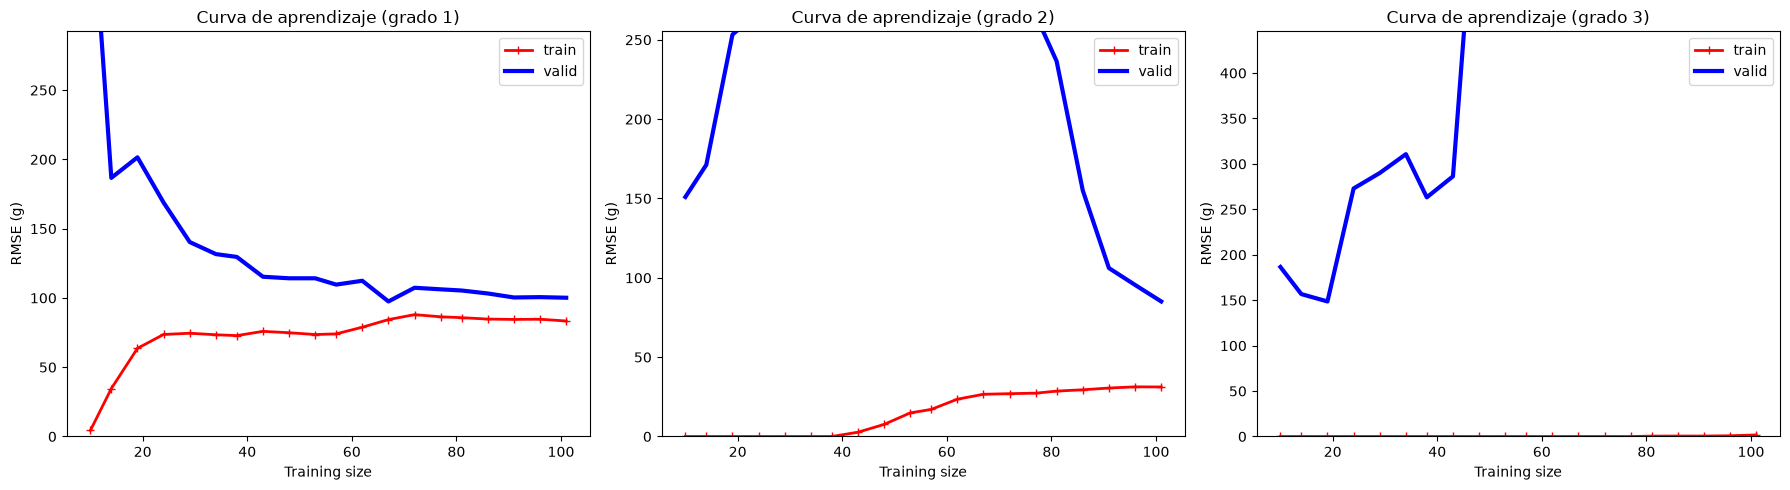

In [ ]:
from sklearn.model_selection import learning_curve, KFold
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

def curva_aprendizaje(X, y, grado, ax):
    """Dibuja la curva de aprendizaje de una regresión polinómica del grado indicado en el gráfico ax."""

    # Generamos las variables polinómicas del grado indicado
    poly = PolynomialFeatures(degree=grado, include_bias=False)
    X_poly = poly.fit_transform(X)

    # Generamos la curva de aprendizaje: entrena el modelo con cantidades crecientes de datos
    # y, para cada cantidad, mide el error en train y en validación mediante validación cruzada
    train_sizes, train_scores, valid_scores = learning_curve(
        LinearRegression(), X_poly, y,
        train_sizes=np.linspace(0.1, 1.0, 20),                # 20 tamaños, del 10 % al 100 % de cada fold de entrenamiento
        cv=KFold(n_splits=5, shuffle=True, random_state=42),  # 5 folds, mezclando las filas, con semilla fija
        scoring="neg_root_mean_squared_error")                

    # learning_curve devuelve:
    #   train_sizes: número de muestras usadas en cada punto de la curva (20 valores)
    #   train_scores: tabla de 20 filas (una por tamaño) y 5 columnas (una por fold)
    #   valid_scores: igual, pero con el error sobre el fold de validación
    # mean(axis=1) hace la media de cada fila, es decir, de los 5 folds para cada tamaño
    # El signo negativo vuelve a poner los errores en positivo
    train_errors = -train_scores.mean(axis=1)
    valid_errors = -valid_scores.mean(axis=1)

    # Gráfica: error de train (rojo) y de validación (azul) según el número de muestras de entrenamiento
    ax.plot(train_sizes, train_errors, "r-+", linewidth=2, label="train")  # "r-+": línea roja con marcadores +
    ax.plot(train_sizes, valid_errors, "b-", linewidth=3, label="valid")   # "b-": línea azul continua

    # Limitamos el eje Y para que los errores enormes de los primeros puntos no aplasten el resto de la curva
    ax.set_ylim(0, 3 * valid_errors.min())

    ax.set_xlabel("Training size")
    ax.set_ylabel("RMSE (g)")
    ax.set_title(f"Curva de aprendizaje (grado {grado})")
    ax.legend()

# Creamos una figura con 3 gráficos en una fila, uno para cada grado
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# zip empareja cada gráfico con un grado: (axes[0], 1), (axes[1], 2), (axes[2], 3)
# y para cada pareja dibujamos la curva de aprendizaje en su gráfico correspondiente
# Usamos solo el conjunto de entrenamiento: el test se reserva para la evaluación final
for ax, grado in zip(axes, [1, 2, 3]):
    curva_aprendizaje(X_train_cod_species_scal, y_train, grado, ax)

plt.tight_layout()  # ajusta los márgenes para que no se solapen títulos y etiquetas
plt.show()

## Regularización ?